# Python DA Assignment 2 - Data Visualization

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the first five rows
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [4]:
# Inspection and Properties
print("Shape:", df.shape)
print("Data Types:\n", df.dtypes)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Shape: (6433, 14)
Data Types:
 pickup             datetime64[ns]
dropoff            datetime64[ns]
passengers                  int64
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                      object
payment                    object
pickup_zone                object
dropoff_zone               object
pickup_borough             object
dropoff_borough            object
dtype: object
Number of Rows: 6433
Number of Columns: 14


In [27]:
# Check Missing Values
print("Missing Values:\n", df.isnull().sum())

# Identify Columns with Missing Values
print("\nColumns with Missing Values:")
print(df.columns[df.isnull().any()].tolist())

Missing Values:
 pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Columns with Missing Values:
['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']


In [28]:
# Handling Missing Values

# Remove Rows with Missing Values in Essential Columns
df = df.dropna(subset=["pickup", "fare", "distance"])

# Fill Missing Numerical Values Using Median
numerical_columns = df.select_dtypes(include=np.number).columns

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill Missing Categorical Values Using Mode
categorical_columns = df.select_dtypes(include=["object", "category"]).columns

for col in categorical_columns:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

# Check Missing Values After Handling
print("Missing Values After Handling:\n", df.isnull().sum())

Missing Values After Handling:
 pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


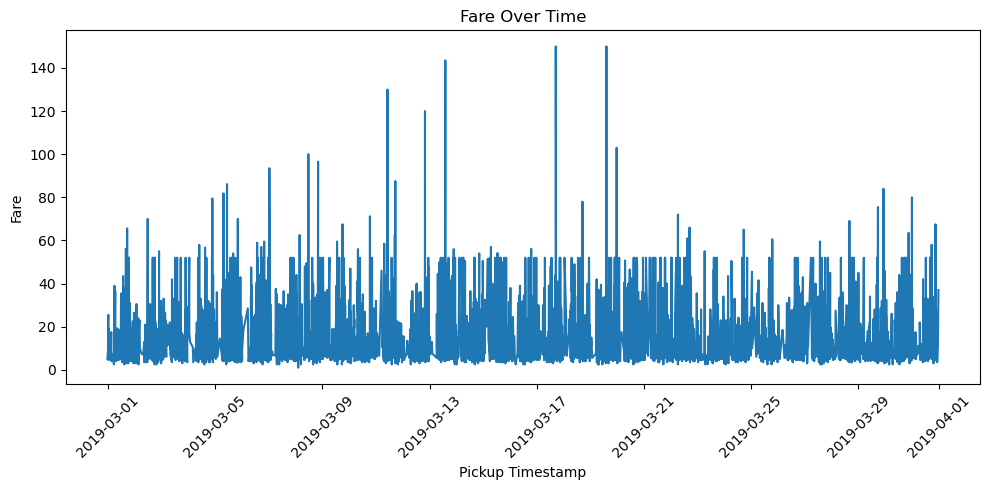

In [5]:
# Line Chart - Fare Over Time

# Convert Pickup Column to Datetime
df["pickup"] = pd.to_datetime(df["pickup"])

# Sort Data by Pickup Timestamp
df_sorted = df.sort_values("pickup")
# Plot Line Chart
plt.figure(figsize=(10, 5))
plt.plot(df_sorted["pickup"], df_sorted["fare"])
plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

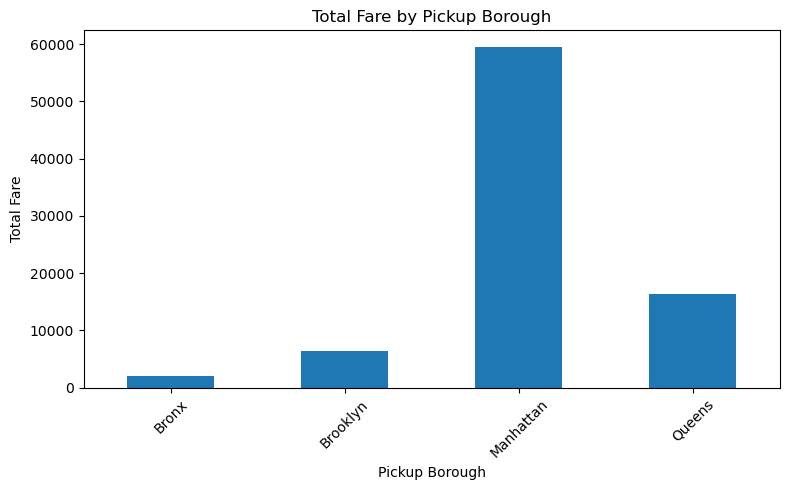

In [8]:
# Bar Chart - Total Fare by Pickup Borough

borough_fare = df.groupby("pickup_borough", observed=True)["fare"].sum()
borough_fare.plot(kind="bar", figsize=(8, 5))
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

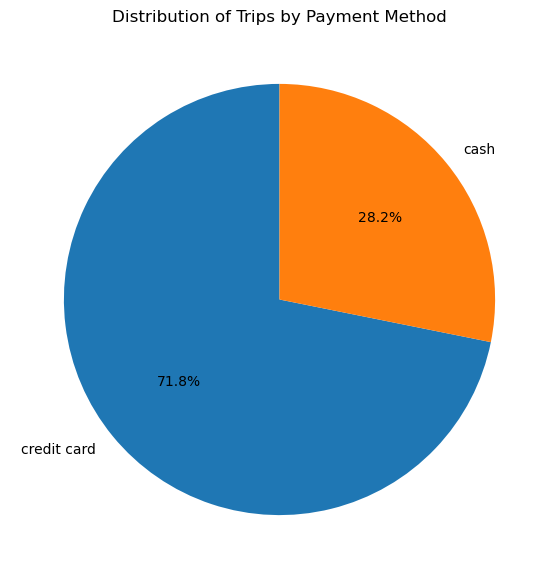

In [9]:
# Pie Chart - Distribution of Trips by Payment Method

payment_counts = df["payment"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90)
plt.title("Distribution of Trips by Payment Method")
plt.show()

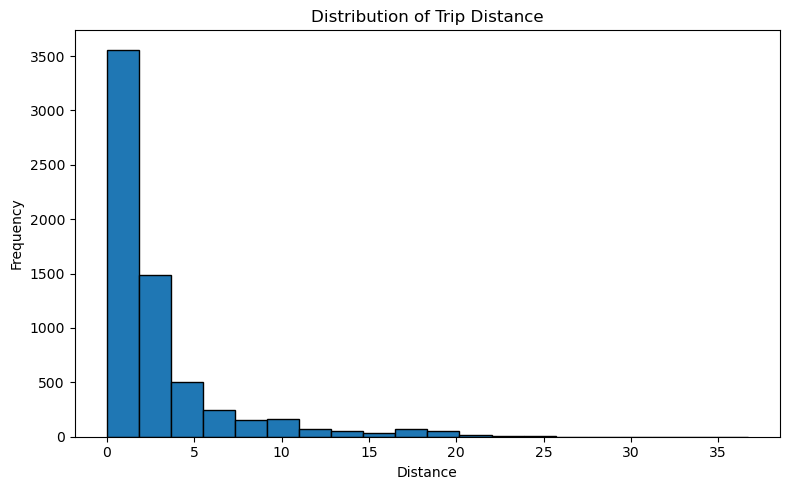

In [14]:
# Histogram - Distribution of Distance

plt.figure(figsize=(8, 5))
plt.hist(df["distance"], bins=20, edgecolor="black")
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

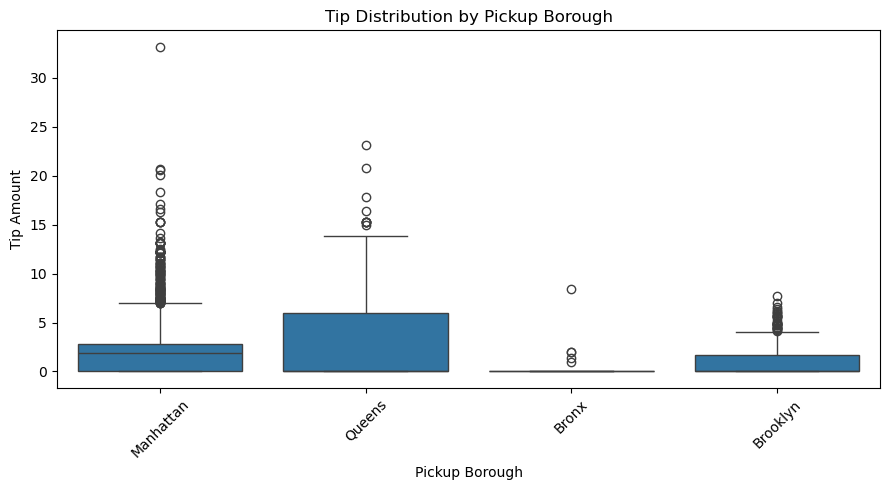

In [11]:
# Box Plot - Tip Amount by Pickup Borough

box_data = df.dropna(subset=["pickup_borough", "tip"])
plt.figure(figsize=(9, 5))
sns.boxplot(data=box_data,
    x="pickup_borough",
    y="tip")
plt.title("Tip Distribution by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

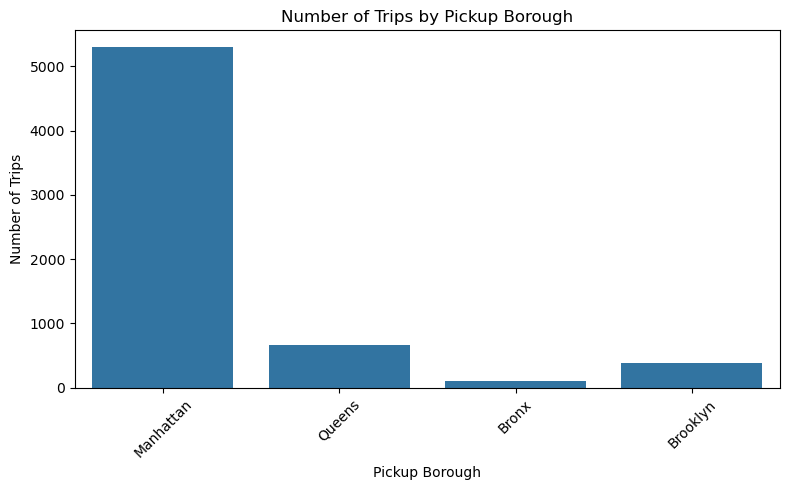

In [16]:
# Count Plot - Number of Trips by Pickup Borough

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="pickup_borough")
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

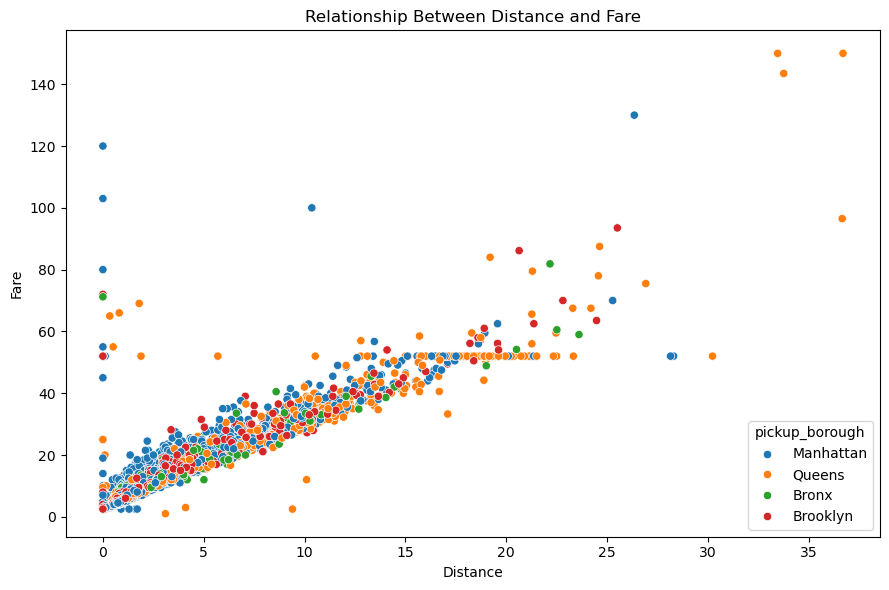

In [15]:
# Scatter Plot - Distance vs Fare

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df,
    x="distance",
    y="fare",
    hue="pickup_borough")
plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

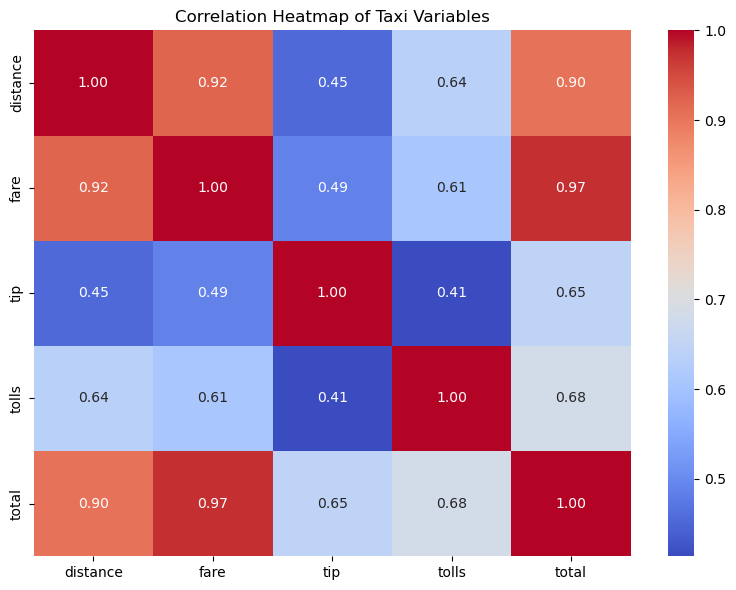

In [16]:
# Heatmap - Correlation Between Numerical Variables

numeric_data = df[["distance", "fare", "tip", "tolls", "total"]]
correlation_matrix = numeric_data.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f")
plt.title("Correlation Heatmap of Taxi Variables")
plt.tight_layout()
plt.show()

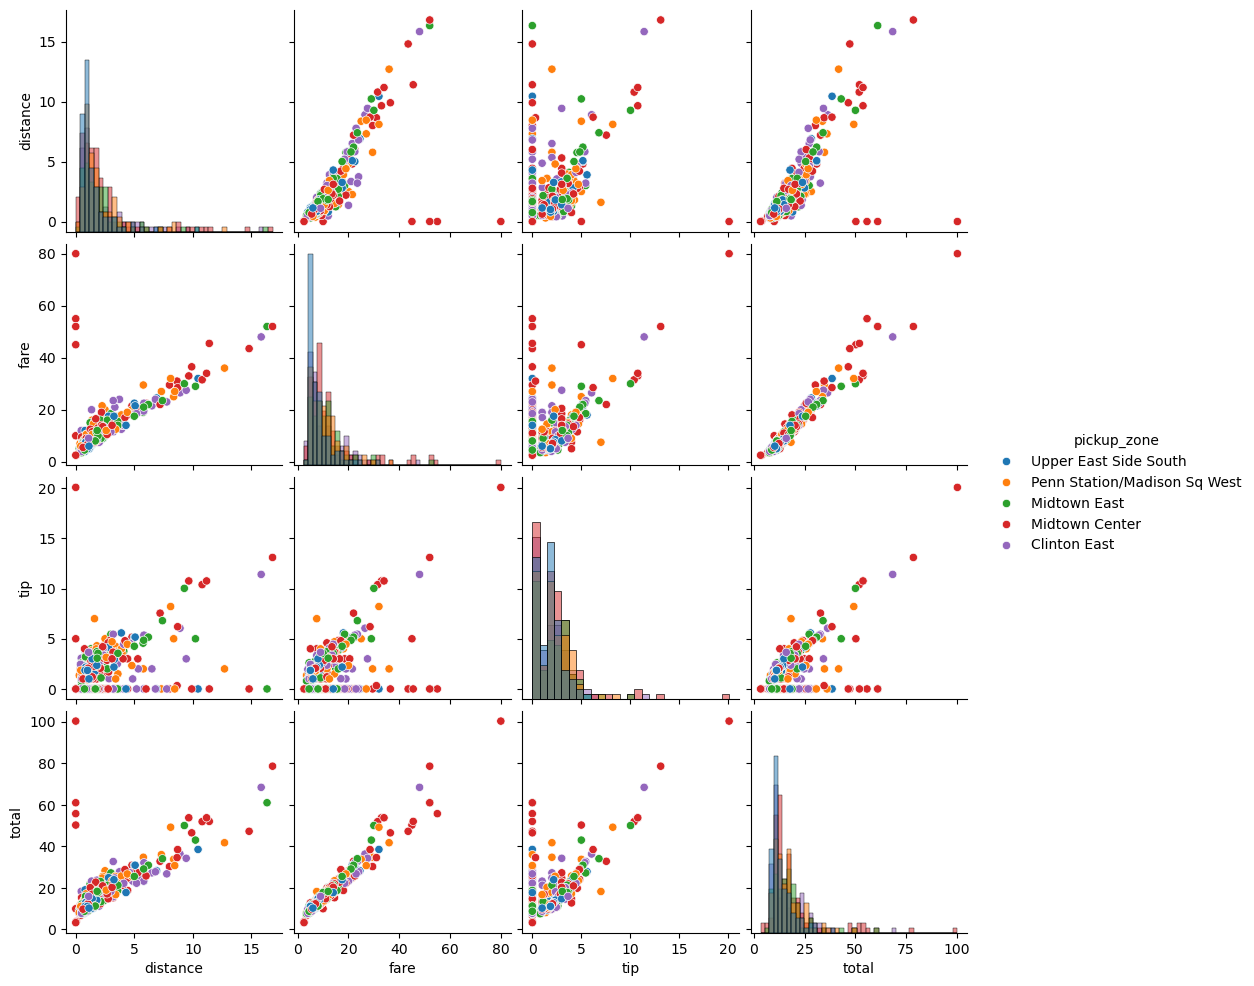

In [8]:
# Pair Plot - Pairwise Relationships

pair_data = df[["distance", "fare", "tip", "total", "pickup_zone"]].copy()
pair_data = pair_data.dropna()
top_zones = pair_data["pickup_zone"].value_counts().head(5).index
pair_data = pair_data[pair_data["pickup_zone"].isin(top_zones)]
pair_data = pair_data.sample(n=min(500, len(pair_data)), random_state=42)
sns.pairplot(pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist")
plt.show()

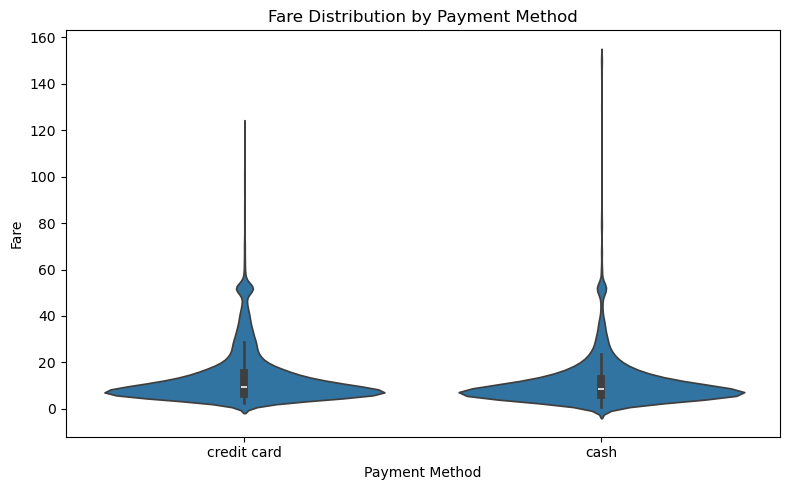

In [31]:
# Violin Plot - Fare Distribution by Payment Method

violin_data = df.dropna(subset=["payment", "fare"])
plt.figure(figsize=(8, 5))
sns.violinplot(data=violin_data,
    x="payment",
    y="fare")
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()